# Avance 2 — Modelo Relacional
### Proyecto Integrador Módulo 3 — TechCore / DataVision Analytics

Este notebook construye el modelo relacional de ventas de TechCore a partir del dataset
limpio exportado desde Power Query en el Avance 1 (`ventasTransformed.csv`).

**Contenido:**
1. Carga del dataset limpio
2. Control de calidad adicional (hallazgos detectados en esta etapa)
3. Construcción de las tablas: Ciudades, Sucursales, Vendedores, Clientes, Productos, Facturas, DetalleFacturas
4. Validación de integridad referencial
5. Reportes exploratorios rápidos
6. Diagrama entidad-relación
7. Exportación a `modeloVentas.xlsx`

## 1. Carga del dataset limpio (Avance 1)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Works whether Jupyter is launched from the repository root or /notebooks
DATA_DIR = Path('data') if Path('data').exists() else Path('../data')

df = pd.read_csv(DATA_DIR / 'ventas_transformed.csv')
print("Filas cargadas:", len(df))
print("Columnas:", list(df.columns))
assert df['VentaID'].is_unique, "VentaID no es unico, revisar Avance 1"
df.head(3)

Filas cargadas: 30000
Columnas: ['VentaID', 'FechaVenta', 'HoraVenta', 'SucursalNombre', 'CiudadSucursal', 'VendedorNombre', 'ClienteNombre', 'GeneroCliente', 'EdadCliente', 'EmailCliente', 'TelefonoCliente', 'DireccionCliente', 'MetodoPago', 'NombreProducto1', 'MarcaProducto1', 'CantidadProducto1', 'PrecioUnitarioProducto1', 'SubtotalProducto1', 'NombreProducto2', 'MarcaProducto2', 'CantidadProducto2', 'PrecioUnitarioProducto2', 'SubtotalProducto2', 'NombreProducto3', 'MarcaProducto3', 'CantidadProducto3', 'PrecioUnitarioProducto3', 'SubtotalProducto3', 'DescuentoVenta', 'TotalVenta', 'AñoVenta']


,VentaID,FechaVenta,HoraVenta,SucursalNombre,CiudadSucursal,VendedorNombre,ClienteNombre,GeneroCliente,EdadCliente,EmailCliente,...,PrecioUnitarioProducto2,SubtotalProducto2,NombreProducto3,MarcaProducto3,CantidadProducto3,PrecioUnitarioProducto3,SubtotalProducto3,DescuentoVenta,TotalVenta,AñoVenta
0,240,"2021-12-07 00:00:00,000","1899-12-30 23:28:42,000",Techcore Medellín #2,Medellín,Claudia Sastre-Quintero,Pánfilo Salazar,M,25,panfilo11@yahoo.com,...,0,0,No Aplica,No Aplica,0,0,0,0,52000000,2021
1,637,"2017-07-15 00:00:00,000","1899-12-30 23:02:30,000",Techcore Medellín #1,Medellín,Ana Sofía Llopis Blázquez,Crescencia Gutierrez Gimenez,F,18,crescencia98@hotmail.com,...,0,0,No Aplica,No Aplica,0,0,0,0,52000000,2017
2,921,"2025-06-16 00:00:00,000","1899-12-30 19:32:20,000",Techcore Bogotá #1,Bogotá,Poncio Gabriel Poza Acedo,Agustina Valcárcel Marco,F,25,agustina17@hotmail.com,...,0,0,No Aplica,No Aplica,0,0,0,0,52000000,2025


## 2. Control de calidad adicional

Al preparar el modelo relacional se detectaron **tres inconsistencias** que no habían
quedado resueltas en la limpieza de Power Query (Avance 1). Se documentan y corrigen aquí
porque afectan directamente el diseño de las tablas `Productos` y `Facturas`.

### 2.1 Typo de marca: "Razer" vs "Razor"
Los 4 modelos Razer (Blade 15, Blade 17, Blade Stealth 13, Book 13) aparecen con dos grafías
distintas de la marca. Se normalizan a `"Razer"`.

### 2.2 Precio unitario inflado x10 en ventas con Cantidad = 10 o 20
En las líneas de producto donde `CantidadProducto` es 10 o 20 (en vez de 1 o 2), el
`PrecioUnitario` quedó multiplicado por 10, mientras que el `Subtotal` de esa línea es correcto.
Se confirmó comparando `Subtotal` contra `PrecioUnitario × Cantidad`. La corrección aplicada:
recalcular `PrecioUnitario = Subtotal / Cantidad` para **todas** las líneas (fórmula única y
consistente, no solo para las filas afectadas). Esto afecta 30.059 de 60.059 líneas de detalle.

### 2.3 `TotalVenta` no reconcilia con el detalle de la factura
La columna `TotalVenta` del dataset original **no coincide con ningún registro** (0 de 30.000)
al compararla contra `suma(Subtotal de línea) − DescuentoVenta`. Es decir, es un valor poco
confiable. Se conserva como `TotalVentaOriginal` solo a modo de trazabilidad, y se agrega
`TotalVentaCalculado` (a partir del detalle de factura) como el valor que debe usarse en los
KPIs del dashboard del Avance 3.

In [2]:
# 2.1 Normalizar marca Razer/Razor
for i in [1,2,3]:
    col = f'MarcaProducto{i}'
    df[col] = df[col].replace('Razor', 'Razer')

# 2.2 Corregir PrecioUnitario a partir de Subtotal / Cantidad
precio_fix_count = 0
for i in [1,2,3]:
    pcol, ccol, scol = f'PrecioUnitarioProducto{i}', f'CantidadProducto{i}', f'SubtotalProducto{i}'
    mask = df[ccol] > 0
    precio_correcto = df.loc[mask, scol] / df.loc[mask, ccol]
    diff = (df.loc[mask, pcol] != precio_correcto)
    precio_fix_count += diff.sum()
    df.loc[mask, pcol] = precio_correcto

print(f"Precios unitarios corregidos: {precio_fix_count}")

Precios unitarios corregidos: 30059


## 3. Construcción de las tablas del modelo relacional

Se identificaron 7 entidades: **Ciudades, Sucursales, Vendedores, Clientes, Productos,
Facturas y DetalleFacturas**. El dataset original viene en formato ancho (hasta 3 productos
por venta en columnas separadas), por lo que se aplica un *unpivot* para pasar cada producto
vendido a una fila propia en `DetalleFacturas`.

**Supuestos de modelado:**
- `ClienteID` se identifica por la combinación `(Nombre, Email)` — se verificó que dentro de
  cada combinación el género, teléfono, dirección y edad son siempre consistentes.
- `ProductoID` se identifica por `(Nombre, Marca)`, ya normalizada la marca.
- Se asume 1 vendedor por sucursal y 1 sucursal por ciudad (verificado: sin excepciones en los datos).
- El descuento (`DescuentoVenta`) viene a nivel de factura, no de línea. Para poblar el campo
  `Descuento` de `DetalleFacturas` que pide la consigna, se prorratea proporcionalmente según
  la participación del subtotal de cada línea en el total de la factura (`DescuentoAsignado`).

In [3]:
# --- Ciudades ---
ciudades_unicas = sorted(df['CiudadSucursal'].dropna().unique())
Ciudades = pd.DataFrame({
    'CiudadID': range(1, len(ciudades_unicas) + 1),
    'NombreCiudad': ciudades_unicas
})
ciudad_map = dict(zip(Ciudades['NombreCiudad'], Ciudades['CiudadID']))
Ciudades

,CiudadID,NombreCiudad
0,1,Bogotá
1,2,Cali
2,3,Medellín
3,4,Pereira


In [4]:
# --- Sucursales ---
suc_df = df[['SucursalNombre', 'CiudadSucursal']].drop_duplicates().sort_values('SucursalNombre').reset_index(drop=True)
Sucursales = pd.DataFrame({
    'SucursalID': range(1, len(suc_df) + 1),
    'NombreSucursal': suc_df['SucursalNombre'],
    'CiudadID': suc_df['CiudadSucursal'].map(ciudad_map)
})
sucursal_map = dict(zip(Sucursales['NombreSucursal'], Sucursales['SucursalID']))
Sucursales

,SucursalID,NombreSucursal,CiudadID
0,1,Techcore Bogotá #1,1
1,2,Techcore Bogotá #2,1
2,3,Techcore Cali,2
3,4,Techcore Medellín #1,3
4,5,Techcore Medellín #2,3
5,6,Techcore Pereira,4


In [5]:
# --- Vendedores ---
vend_df = df[['VendedorNombre', 'SucursalNombre']].drop_duplicates().sort_values('VendedorNombre').reset_index(drop=True)
Vendedores = pd.DataFrame({
    'VendedorID': range(1, len(vend_df) + 1),
    'NombreVendedor': vend_df['VendedorNombre'],
    'SucursalID': vend_df['SucursalNombre'].map(sucursal_map)
})
vendedor_map = dict(zip(Vendedores['NombreVendedor'], Vendedores['VendedorID']))
Vendedores.head()

,VendedorID,NombreVendedor,SucursalID
0,1,Almudena Adelaida Lledó Garrido,5
1,2,Amílcar Ortega-Alberto,6
2,3,Ana Sofía Llopis Blázquez,4
3,4,Anacleto Morera Segovia,6
4,5,Armida Azorin Plaza,2


In [6]:
# --- Clientes (clave de identidad: Nombre + Email) ---
cli_cols = ['ClienteNombre','EmailCliente','GeneroCliente','EdadCliente','TelefonoCliente','DireccionCliente']
cli_df = df[cli_cols].drop_duplicates(subset=['ClienteNombre','EmailCliente']).sort_values('ClienteNombre').reset_index(drop=True)
Clientes = pd.DataFrame({
    'ClienteID': range(1, len(cli_df) + 1),
    'Nombre': cli_df['ClienteNombre'],
    'Genero': cli_df['GeneroCliente'],
    'Edad': cli_df['EdadCliente'],
    'Telefono': cli_df['TelefonoCliente'],
    'Email': cli_df['EmailCliente'],
    'Direccion': cli_df['DireccionCliente']
})
cliente_map = {(r['Nombre'], r['Email']): r['ClienteID'] for _, r in Clientes.iterrows()}
print("Clientes unicos:", len(Clientes))
Clientes.head()

Clientes unicos: 17453


,ClienteID,Nombre,Genero,Edad,Telefono,Email,Direccion
0,1,Aarón Aguilera-Esteban,M,39,+34806 28 91 01,aaron78@yahoo.com,cra 75 #43-69
1,2,Aarón Asenjo Reguera,M,30,+34714 538 644,aaron13@gmail.com,cll 16 #89-59
2,3,Aarón Asensio Martín,M,34,+34886 38 77 52,aaron14@yahoo.com,cll 93 #99-72
3,4,Aarón Blazquez Fabregat,M,46,+34 888911631,aaron6@gmail.com,cra 2 #45-67
4,5,Aarón Cabrera Pedraza,M,34,+34 878 04 20 66,aaron36@yahoo.com,cll 36 #8-20


In [7]:
# --- Unpivot de productos (formato ancho -> formato largo) ---
detalle_rows = []
for i in [1,2,3]:
    tmp = df[['VentaID', f'NombreProducto{i}', f'MarcaProducto{i}',
              f'CantidadProducto{i}', f'PrecioUnitarioProducto{i}', f'SubtotalProducto{i}']].copy()
    tmp.columns = ['VentaID','Nombre','Marca','Cantidad','PrecioUnitario','Subtotal']
    detalle_rows.append(tmp)
detalle_long = pd.concat(detalle_rows, ignore_index=True)
detalle_long = detalle_long[detalle_long['Nombre'] != 'No Aplica'].reset_index(drop=True)
print("Lineas de detalle:", len(detalle_long))

Lineas de detalle: 60059


In [8]:
# --- Productos ---
prod_df = detalle_long[['Nombre','Marca','PrecioUnitario']].drop_duplicates(subset=['Nombre','Marca']).sort_values('Nombre').reset_index(drop=True)
Productos = pd.DataFrame({
    'ProductoID': range(1, len(prod_df) + 1),
    'Nombre': prod_df['Nombre'],
    'Marca': prod_df['Marca'],
    'Precio': prod_df['PrecioUnitario']
})
producto_map = {(r['Nombre'], r['Marca']): r['ProductoID'] for _, r in Productos.iterrows()}
print("Productos unicos:", len(Productos))
Productos

Productos unicos: 40


,ProductoID,Nombre,Marca,Precio
0,1,Acer Aspire 5,Acer,2000000
1,2,Acer Nitro 5,Acer,4000000
2,3,Acer Predator Helios 300,Acer,5600000
3,4,Acer Swift 3,Acer,2600000
4,5,Apple MacBook Air M1,Apple,5500000
5,6,Apple MacBook Pro 14,Apple,8000000
6,7,Apple MacBook Pro 16,Apple,9600000
7,8,Apple iMac 24,Apple,6400000
8,9,Asus ROG Strix G15,Asus,6400000
9,10,Asus TUF Gaming A15,Asus,4800000


In [9]:
# --- Facturas (encabezado de cada venta) ---
df['ClienteKey'] = list(zip(df['ClienteNombre'], df['EmailCliente']))
df['HoraVentaLimpia'] = df['HoraVenta'].str.split(' ').str[1]

Facturas = pd.DataFrame({
    'FacturaID': df['VentaID'],
    'Fecha': pd.to_datetime(df['FechaVenta'], format='mixed').dt.date,
    'Hora': df['HoraVentaLimpia'],
    'SucursalID': df['SucursalNombre'].map(sucursal_map),
    'ClienteID': df['ClienteKey'].map(cliente_map),
    'VendedorID': df['VendedorNombre'].map(vendedor_map),
    'MetodoPago': df['MetodoPago'],
    'DescuentoVenta': df['DescuentoVenta'],
    'TotalVentaOriginal': df['TotalVenta']
}).reset_index(drop=True)
Facturas.head()

,FacturaID,Fecha,Hora,SucursalID,ClienteID,VendedorID,MetodoPago,DescuentoVenta,TotalVentaOriginal
0,240,2021-12-07,"23:28:42,000",5,13941,9,Tarjeta Crédito,0,52000000
1,637,2017-07-15,"23:02:30,000",4,3954,3,Tarjeta Crédito,0,52000000
2,921,2025-06-16,"19:32:20,000",1,362,29,Tarjeta Crédito,0,52000000
3,1096,2023-03-27,"07:53:12,000",4,4179,14,Tarjeta Crédito,0,52000000
4,1106,2017-02-27,"17:50:40,000",2,8368,18,Tarjeta Crédito,0,52000000


In [10]:
# --- DetalleFacturas ---
detalle_long['ProductoKey'] = list(zip(detalle_long['Nombre'], detalle_long['Marca']))
detalle_long['ProductoID'] = detalle_long['ProductoKey'].map(producto_map)

# Descuento prorrateado por participacion del subtotal de cada linea
subtotal_por_factura = detalle_long.groupby('VentaID')['Subtotal'].transform('sum')
descuento_factura = detalle_long['VentaID'].map(dict(zip(df['VentaID'], df['DescuentoVenta'])))
proporcion = np.where(subtotal_por_factura > 0, detalle_long['Subtotal'] / subtotal_por_factura, 0)
detalle_long['DescuentoAsignado'] = (descuento_factura * proporcion).round(2)

DetalleFacturas = pd.DataFrame({
    'DetalleID': range(1, len(detalle_long) + 1),
    'FacturaID': detalle_long['VentaID'],
    'ProductoID': detalle_long['ProductoID'],
    'Cantidad': detalle_long['Cantidad'],
    'PrecioUnitario': detalle_long['PrecioUnitario'],
    'Subtotal': detalle_long['Subtotal'],
    'DescuentoAsignado': detalle_long['DescuentoAsignado']
})
DetalleFacturas.head()

,DetalleID,FacturaID,ProductoID,Cantidad,PrecioUnitario,Subtotal,DescuentoAsignado
0,1,240,20,1,5200000,5200000,0.0
1,2,637,20,1,5200000,5200000,0.0
2,3,921,20,1,5200000,5200000,0.0
3,4,1096,20,1,5200000,5200000,0.0
4,5,1106,20,1,5200000,5200000,0.0


In [11]:
# Total recalculado y confiable a partir del detalle (ver hallazgo 2.3)
subtotal_por_venta = DetalleFacturas.groupby('FacturaID')['Subtotal'].sum().rename('SubtotalCalculado')
Facturas = Facturas.merge(subtotal_por_venta, left_on='FacturaID', right_index=True, how='left')
Facturas['TotalVentaCalculado'] = Facturas['SubtotalCalculado'] - Facturas['DescuentoVenta']
inconsist = (Facturas['TotalVentaCalculado'] != Facturas['TotalVentaOriginal']).sum()
print(f"Facturas donde TotalVentaOriginal difiere del calculado: {inconsist} de {len(Facturas)}")
Facturas = Facturas.drop(columns=['SubtotalCalculado'])
Facturas.head()

Facturas donde TotalVentaOriginal difiere del calculado: 30000 de 30000


,FacturaID,Fecha,Hora,SucursalID,ClienteID,VendedorID,MetodoPago,DescuentoVenta,TotalVentaOriginal,TotalVentaCalculado
0,240,2021-12-07,"23:28:42,000",5,13941,9,Tarjeta Crédito,0,52000000,5200000
1,637,2017-07-15,"23:02:30,000",4,3954,3,Tarjeta Crédito,0,52000000,5200000
2,921,2025-06-16,"19:32:20,000",1,362,29,Tarjeta Crédito,0,52000000,5200000
3,1096,2023-03-27,"07:53:12,000",4,4179,14,Tarjeta Crédito,0,52000000,5200000
4,1106,2017-02-27,"17:50:40,000",2,8368,18,Tarjeta Crédito,0,52000000,5200000


## 4. Validación de integridad referencial

Se verifica que no existan registros huérfanos: todo `FacturaID`, `ProductoID`, `SucursalID`,
`ClienteID`, `VendedorID` y `CiudadID` referenciado desde una tabla hija debe existir en su
tabla padre.

In [12]:
errores = []
if not DetalleFacturas['FacturaID'].isin(Facturas['FacturaID']).all():
    errores.append("Hay FacturaID en DetalleFacturas que no existen en Facturas")
if not DetalleFacturas['ProductoID'].isin(Productos['ProductoID']).all():
    errores.append("Hay ProductoID en DetalleFacturas que no existen en Productos")
if not Facturas['SucursalID'].isin(Sucursales['SucursalID']).all():
    errores.append("Hay SucursalID en Facturas que no existen en Sucursales")
if not Facturas['ClienteID'].isin(Clientes['ClienteID']).all():
    errores.append("Hay ClienteID en Facturas que no existen en Clientes")
if not Facturas['VendedorID'].isin(Vendedores['VendedorID']).all():
    errores.append("Hay VendedorID en Facturas que no existen en Vendedores")
if not Vendedores['SucursalID'].isin(Sucursales['SucursalID']).all():
    errores.append("Hay SucursalID en Vendedores que no existen en Sucursales")
if not Sucursales['CiudadID'].isin(Ciudades['CiudadID']).all():
    errores.append("Hay CiudadID en Sucursales que no existen en Ciudades")
if Facturas['ClienteID'].isna().any():
    errores.append("Hay Facturas sin ClienteID asignado")
if Facturas['VendedorID'].isna().any():
    errores.append("Hay Facturas sin VendedorID asignado")
if DetalleFacturas['ProductoID'].isna().any():
    errores.append("Hay lineas de DetalleFacturas sin ProductoID asignado")

if errores:
    print("ERRORES DE INTEGRIDAD ENCONTRADOS:")
    for e in errores:
        print(" -", e)
else:
    print("Integridad referencial OK: sin registros huerfanos en ninguna relacion.")

Integridad referencial OK: sin registros huerfanos en ninguna relacion.


## 5. Reportes exploratorios rápidos

Se calculan dos reportes pedidos en la consigna: ventas totales por marca y el top 10 de
productos más vendidos (por cantidad). Ambos usan las tablas ya limpias y validadas.

In [13]:
detalle_full = DetalleFacturas.merge(Productos, on='ProductoID')

print(f"Ventas totales (TotalVentaCalculado): {Facturas['TotalVentaCalculado'].sum():,.0f}")
print(f"Ticket promedio: {Facturas['TotalVentaCalculado'].mean():,.0f}")
print()

ventas_por_marca = detalle_full.groupby('Marca')['Subtotal'].sum().sort_values(ascending=False)
print("Ventas totales por marca:")
ventas_por_marca

Ventas totales (TotalVentaCalculado): 2,572,205,552,196
Ticket promedio: 85,740,185

Ventas totales por marca:


Marca
Lenovo       656165600000
HP           529810000000
Dell         476146600000
Apple        422534400000
Asus         182941400000
Acer         121788800000
Samsung       67596000000
MSI           47754400000
Microsoft     45193600000
Razer         22274800000
Name: Subtotal, dtype: int64

In [14]:
top10_productos = detalle_full.groupby(['Nombre','Marca'])['Cantidad'].sum().sort_values(ascending=False).head(10)
print("Top 10 productos mas vendidos (por cantidad):")
top10_productos

Top 10 productos mas vendidos (por cantidad):


Nombre                     Marca 
HP Spectre x360            HP        41350
Lenovo ThinkPad X1 Carbon  Lenovo    32724
Lenovo Legion 5 Pro        Lenovo    32033
Lenovo Yoga 7i             Lenovo    28605
HP Omen 16                 HP        27781
Lenovo IdeaPad 5           Lenovo    27551
Dell Latitude 7420         Dell      24910
Dell XPS 13                Dell      24812
HP Pavilion 15             HP        22488
Dell Alienware m15         Dell      19939
Name: Cantidad, dtype: int64

In [15]:
print("Resumen de tablas del modelo relacional:")
for name, t in [('Ciudades',Ciudades),('Sucursales',Sucursales),('Vendedores',Vendedores),
                ('Clientes',Clientes),('Productos',Productos),('Facturas',Facturas),
                ('DetalleFacturas',DetalleFacturas)]:
    print(f"  {name}: {len(t)} filas, {len(t.columns)} columnas")

Resumen de tablas del modelo relacional:
  Ciudades: 4 filas, 2 columnas
  Sucursales: 6 filas, 3 columnas
  Vendedores: 30 filas, 3 columnas
  Clientes: 17453 filas, 7 columnas
  Productos: 40 filas, 4 columnas
  Facturas: 30000 filas, 10 columnas
  DetalleFacturas: 60059 filas, 7 columnas


## 6. Diagrama entidad-relación

Modelo en esquema estrella: `Facturas` y `DetalleFacturas` son las tablas de hechos,
rodeadas por las dimensiones `Ciudades → Sucursales → Vendedores`, `Clientes` y `Productos`.
Todas las relaciones son 1:N desde la dimensión hacia la tabla que la referencia.

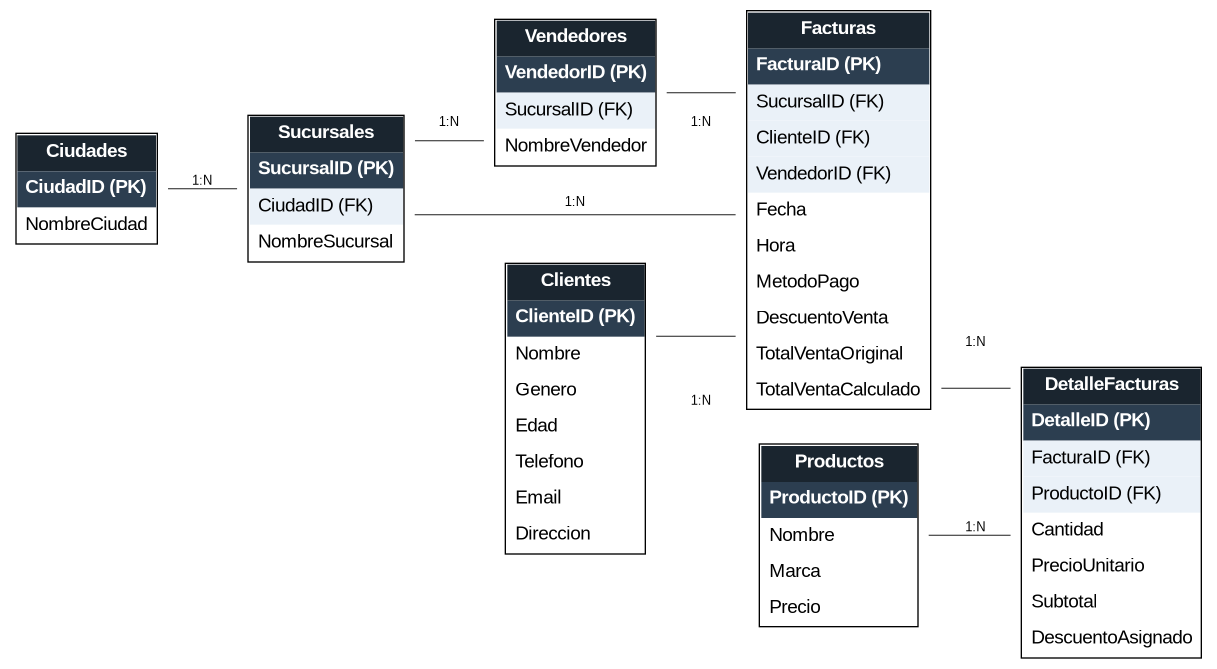

## 7. Exportación a `modeloVentas.xlsx`

Se exportan las 7 tablas, cada una en su propia hoja, listas para importar en Power BI
en el Avance 3.

In [16]:
output_path = DATA_DIR / 'modelo_ventas.xlsx'
with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    Ciudades.to_excel(writer, sheet_name='Ciudades', index=False)
    Sucursales.to_excel(writer, sheet_name='Sucursales', index=False)
    Vendedores.to_excel(writer, sheet_name='Vendedores', index=False)
    Clientes.to_excel(writer, sheet_name='Clientes', index=False)
    Productos.to_excel(writer, sheet_name='Productos', index=False)
    Facturas.to_excel(writer, sheet_name='Facturas', index=False)
    DetalleFacturas.to_excel(writer, sheet_name='DetalleFacturas', index=False)

print(f"{output_path} generado con exito.")

modeloVentas.xlsx generado con exito.


## Conclusiones del Avance 2

- Se construyeron las 7 tablas del modelo relacional a partir de `ventasTransformed.csv`,
  con integridad referencial validada sin registros huérfanos.
- Se detectaron y corrigieron 3 inconsistencias de calidad de datos no resueltas en Avance 1:
  typo de marca Razer/Razor, precio unitario inflado x10 en ventas con cantidad 10/20, y un
  `TotalVenta` original que no reconcilia con el detalle de la factura.
- Para el Avance 3 (dashboard), usar **`TotalVentaCalculado`** como fuente de las medidas DAX
  de ventas totales, no `TotalVentaOriginal`.
- El archivo `modeloVentas.xlsx` queda listo para ser importado como modelo de datos en Power BI.